# Versão modular · mesma referência científica
As funções estão em src/hai_tcc; o notebook apresenta cada passo e seus resultados.
Configuração: configs/baseline.yaml. Saídas: runs/baseline_modular/.
Cada etapa começa em um kernel novo e lê os artefatos salvos em disco.


# 05 — Análise dos resultados | HAI 21.03

Este notebook reúne os resultados produzidos nos notebooks **03_validacao** e
**04_teste**. As tabelas e os gráficos são calculados a partir dos CSVs do projeto.

| Etapa | Arquivos do HAI | Função no experimento |
|---|---|---|
| Treinamento | `test1`, `test2`, `test3` | Ajustar modelos e pré-processamento |
| Validação | `test4` | Escolher os limiares pelo maior F1 |
| Teste | `test5` | Avaliar com os modelos e os limiares fixados |

Essa é a divisão adaptada adotada no trabalho. O RF foi ajustado com registros
normais e de ataque; os dois IFs usaram registros de treinamento selecionados
como normais pelo rótulo. Os limiares dos três modelos utilizaram os rótulos da
validação. Aqui analisamos as decisões já geradas.

**Como executar:** salve este arquivo na pasta `notebooks` do seu projeto,
selecione o kernel `.venv` e execute as células na ordem. Os arquivos de entrada
devem estar na pasta `results`. As novas saídas ficam em
`results/analise_resultados`.


In [1]:
from pathlib import Path
import sys
for BASE_DIR in (Path.cwd(), *Path.cwd().parents):
    if (BASE_DIR / "configs/baseline.yaml").is_file() and (BASE_DIR / "src/hai_tcc").is_dir():
        break
else:
    raise FileNotFoundError("Abra a pasta do projeto.")
if str(BASE_DIR / "src") not in sys.path:
    sys.path.insert(0, str(BASE_DIR / "src"))
from hai_tcc.experiment import abrir_experimento
exp = abrir_experimento(BASE_DIR)
import numpy as np
import pandas as pd

import json
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
exp.exigir("teste")
RESULTS_DIR = exp.resultados
ANALISE_DIR = RESULTS_DIR / 'analise_resultados'
MODELOS = ['RF', 'IF sem PCA', 'IF com PCA']
CORES = {'RF': '#1f77b4', 'IF sem PCA': '#ff7f0e', 'IF com PCA': '#2ca02c'}

arquivos_necessarios = [
    'validacao_inicial.csv',
    'validacao_ajustada.csv',
    'teste_metricas.csv',
    'teste_avaliacao_intervalos.csv',
    'teste_falsos_positivos_por_hora.csv',
]
conferencia = pd.DataFrame({
    'arquivo': arquivos_necessarios,
    'encontrado': [(RESULTS_DIR / nome).is_file() for nome in arquivos_necessarios],
})
display(conferencia)

if not conferencia['encontrado'].all():
    faltantes = conferencia.loc[~conferencia['encontrado'], 'arquivo'].tolist()
    raise FileNotFoundError(
        'Arquivos ausentes: ' + ', '.join(faltantes)
        + '. Confira a pasta do projeto e as exportações dos notebooks 3 e 4.'
    )

ANALISE_DIR.mkdir(parents=True, exist_ok=True)
print('Projeto:', BASE_DIR)
print('Saídas desta análise:', ANALISE_DIR)


,arquivo,encontrado
0,validacao_inicial.csv,True
1,validacao_ajustada.csv,True
2,teste_metricas.csv,True
3,teste_avaliacao_intervalos.csv,True
4,teste_falsos_positivos_por_hora.csv,True


Projeto: /home/samuel/Documents/tcc-hai_modular
Saídas desta análise: /home/samuel/Documents/tcc-hai_modular/runs/baseline_modular/previsoes_e_metricas/analise_resultados


## 1. Reunir e conferir as métricas

Carregamos as métricas antes e depois do ajuste de limiar e as métricas do teste.
A conferência abaixo verifica se as taxas correspondem às contagens da matriz
de confusão. Isso ajuda a evitar a mistura acidental de resultados de execuções
diferentes.

As métricas variam de 0 a 1. Por exemplo, `0.60` corresponde a 60%. As contagens
VP, VN, FP e FN representam registros, e não eventos de ataque.


In [2]:
from hai_tcc.evaluation import METRICAS_TAXA, CONTAGENS, METRICAS, divisao_segura, carregar_metricas
resumos = {
    'Validação inicial': carregar_metricas(RESULTS_DIR / 'validacao_inicial.csv'),
    'Validação ajustada': carregar_metricas(RESULTS_DIR / 'validacao_ajustada.csv'),
    'Teste': carregar_metricas(RESULTS_DIR / 'teste_metricas.csv'),
}
comparacao_etapas = pd.concat(
    {etapa: tabela.T for etapa, tabela in resumos.items()},
    names=['Etapa', 'Modelo'],
)
display(comparacao_etapas[['Acurácia', 'Precisão', 'Recall', 'F1-score']].round(4))
comparacao_etapas.to_csv(ANALISE_DIR / 'comparacao_etapas.csv')

teste = resumos['Teste'].T.copy()
for coluna in CONTAGENS:
    teste[coluna] = teste[coluna].astype(int)
normais_teste = int(teste.loc[MODELOS[0], 'Verdadeiros negativos'] + teste.loc[MODELOS[0], 'Falsos positivos'])
ataques_teste = int(teste.loc[MODELOS[0], 'Verdadeiros positivos'] + teste.loc[MODELOS[0], 'Falsos negativos'])
total_teste = normais_teste + ataques_teste
print(f'Teste: {total_teste:,} registros; {normais_teste:,} normais; {ataques_teste:,} de ataque.')


Metrica                        Acurácia  Precisão  Recall  F1-score
Etapa              Modelo                                          
Validação inicial  RF            0.9772    0.8832  0.2550    0.3957
                   IF sem PCA    0.5985    0.0579  0.8349    0.1083
                   IF com PCA    0.9485    0.3099  0.6206    0.4134
Validação ajustada RF            0.9799    0.6708  0.6145    0.6414
                   IF sem PCA    0.9405    0.2125  0.3829    0.2733
                   IF com PCA    0.9826    0.7995  0.5376    0.6429
Teste              RF            0.8747    0.1095  0.6054    0.1855
                   IF sem PCA    0.9416    0.1608  0.3500    0.2203
                   IF com PCA    0.9772    0.5211  0.4134    0.4611

Teste: 92,401 registros; 90,224 normais; 2,177 de ataque.


## 2. O que mudou com o ajuste de limiar?

A tabela compara as decisões originais e as decisões com os cortes escolhidos
no `test4`. Um F1 maior pode acompanhar uma redução do recall, caso a redução
dos falsos positivos compense essa mudança no critério escolhido.

O ajuste altera a decisão produzida a partir da pontuação. As árvores, o
padronizador e o PCA continuam aqueles do treinamento.


In [3]:
inicial = resumos['Validação inicial']
ajustada = resumos['Validação ajustada']
efeito_limiar = pd.DataFrame({
    'F1 inicial': inicial.loc['F1-score'],
    'F1 ajustado': ajustada.loc['F1-score'],
    'Variação F1': ajustada.loc['F1-score'] - inicial.loc['F1-score'],
    'Recall inicial': inicial.loc['Recall'],
    'Recall ajustado': ajustada.loc['Recall'],
    'FP inicial': inicial.loc['Falsos positivos'].astype(int),
    'FP ajustado': ajustada.loc['Falsos positivos'].astype(int),
}).reindex(MODELOS)
display(efeito_limiar.round(4))
efeito_limiar.to_csv(ANALISE_DIR / 'efeito_ajuste_limiar.csv', index_label='Modelo')


,F1 inicial,F1 ajustado,Variação F1,Recall inicial,Recall ajustado,FP inicial,FP ajustado
RF,0.3957,0.6414,0.2457,0.2550,0.6145,39,349
IF sem PCA,0.1083,0.2733,0.1649,0.8349,0.3829,15710,1642
IF com PCA,0.4134,0.6429,0.2295,0.6206,0.5376,1599,156


## 3. Comparar validação ajustada e teste

Os cortes foram escolhidos para obter o maior F1 na validação. Por isso, a
avaliação no teste é necessária para observar seu comportamento em outro
período. Os gráficos usam os cortes já fixados.

Uma queda de desempenho mostra uma diferença entre os períodos avaliados.
Esses números, sozinhos, não estabelecem sua causa.


,Validação ajustada,Teste,Variação F1 (teste - validação)
RF,0.6414,0.1855,-0.4559
IF sem PCA,0.2733,0.2203,-0.0530
IF com PCA,0.6429,0.4611,-0.1818


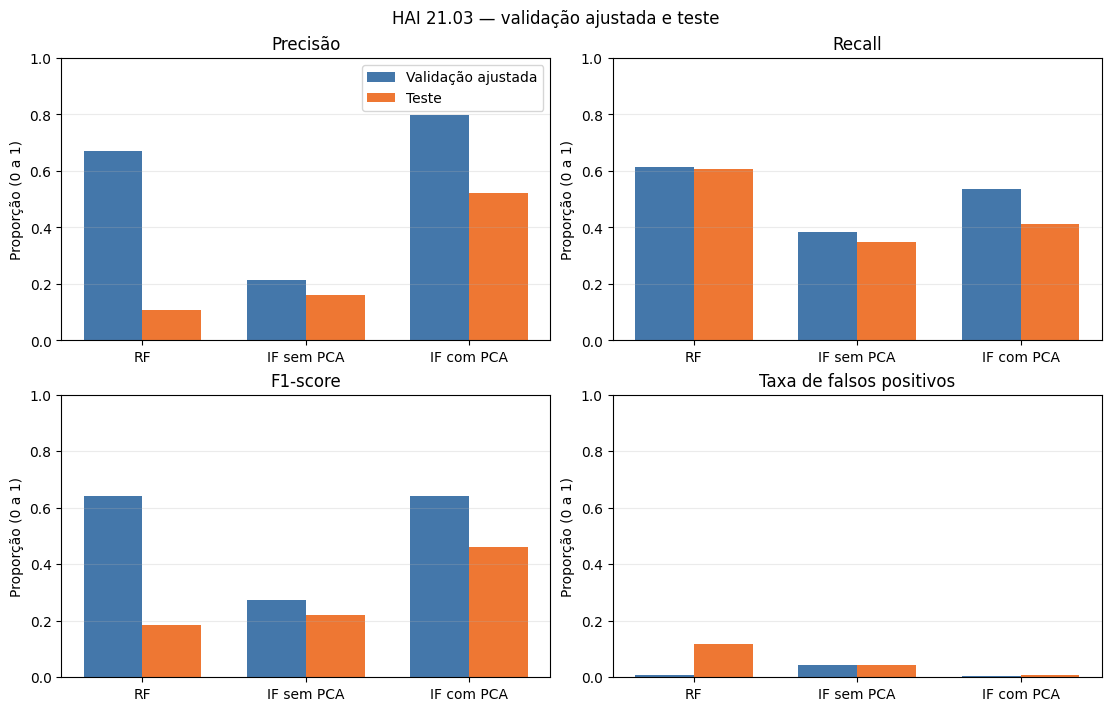

In [4]:
comparacao_f1 = pd.DataFrame({
    'Validação ajustada': ajustada.loc['F1-score'],
    'Teste': resumos['Teste'].loc['F1-score'],
}).reindex(MODELOS)
comparacao_f1['Variação F1 (teste - validação)'] = (
    comparacao_f1['Teste'] - comparacao_f1['Validação ajustada']
)
display(comparacao_f1.round(4))
comparacao_f1.to_csv(ANALISE_DIR / 'f1_validacao_teste.csv', index_label='Modelo')

fig, eixos = plt.subplots(2, 2, figsize=(11, 7), layout='constrained')
x = np.arange(len(MODELOS))
largura = 0.36
for ax, metrica in zip(eixos.flat, ['Precisão', 'Recall', 'F1-score', 'Taxa de falsos positivos']):
    ax.bar(x - largura / 2, ajustada.loc[metrica, MODELOS], largura, label='Validação ajustada', color='#4477aa')
    ax.bar(x + largura / 2, resumos['Teste'].loc[metrica, MODELOS], largura, label='Teste', color='#ee7733')
    ax.set_title(metrica)
    ax.set_xticks(x, MODELOS)
    ax.set_ylabel('Proporção (0 a 1)')
    ax.set_ylim(0, 1)
    ax.grid(axis='y', alpha=0.25)
eixos[0, 0].legend()
fig.suptitle('HAI 21.03 — validação ajustada e teste')
for extensao in ['png', 'pdf']:
    fig.savefig(ANALISE_DIR / f'validacao_teste.{extensao}', dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)


## 4. Examinar o teste e a matriz de confusão

**Linhas da matriz:** classe real. **Colunas:** classe prevista.

| Classe real / prevista | Normal | Ataque |
|---|---|---|
| Normal | VN | FP |
| Ataque | FN | VP |

A referência que prevê tudo como normal ajuda a interpretar a acurácia em um
conjunto desbalanceado. Ela tem recall e F1 iguais a zero para a classe de
ataque. Na precisão, utilizamos a convenção de zero quando não há alertas.


Metrica,Acurácia,Precisão,Recall,F1-score,Falsos positivos,Falsos negativos
RF,0.8747,0.1095,0.6054,0.1855,10718,859
IF sem PCA,0.9416,0.1608,0.3500,0.2203,3978,1415
IF com PCA,0.9772,0.5211,0.4134,0.4611,827,1277


Metrica,Acurácia,Precisão,Recall,F1-score
RF,0.8747,0.1095,0.6054,0.1855
IF sem PCA,0.9416,0.1608,0.3500,0.2203
IF com PCA,0.9772,0.5211,0.4134,0.4611
Sempre normal,0.9764,0.0000,0.0000,0.0000


Prever sempre normal produziria 97.64% de acurácia neste conjunto.


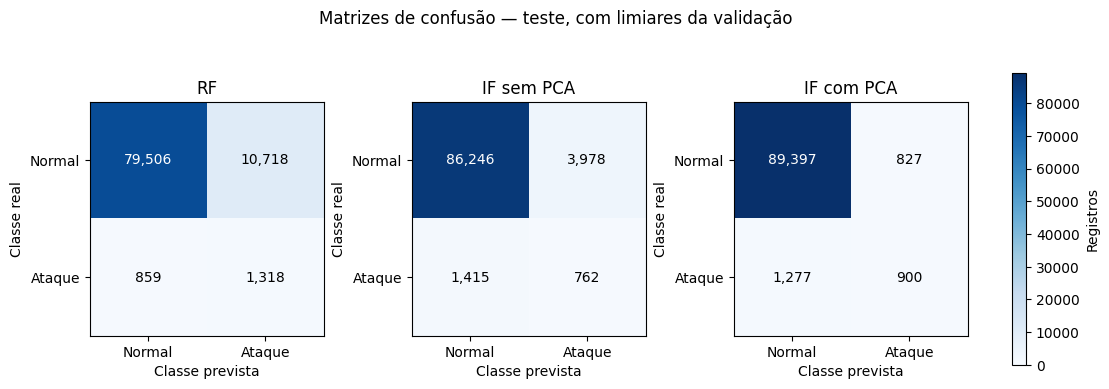

In [5]:
display(teste[['Acurácia', 'Precisão', 'Recall', 'F1-score', 'Falsos positivos', 'Falsos negativos']].round(4))

acuracia_referencia = divisao_segura(normais_teste, total_teste)
referencia = teste[['Acurácia', 'Precisão', 'Recall', 'F1-score']].copy()
referencia.loc['Sempre normal'] = [acuracia_referencia, 0.0, 0.0, 0.0]
display(referencia.round(4))
referencia.to_csv(ANALISE_DIR / 'teste_com_referencia.csv', index_label='Modelo')
print(f'Prever sempre normal produziria {acuracia_referencia:.2%} de acurácia neste conjunto.')

matrizes = {}
for modelo in MODELOS:
    linha = teste.loc[modelo]
    matrizes[modelo] = np.array([
        [linha['Verdadeiros negativos'], linha['Falsos positivos']],
        [linha['Falsos negativos'], linha['Verdadeiros positivos']],
    ], dtype=int)

fig, eixos = plt.subplots(1, 3, figsize=(11, 4), layout='constrained')
maximo = max(matriz.max() for matriz in matrizes.values())
for ax, modelo in zip(eixos, MODELOS):
    matriz = matrizes[modelo]
    imagem = ax.imshow(matriz, cmap='Blues', vmin=0, vmax=maximo)
    for (i, j), valor in np.ndenumerate(matriz):
        ax.text(j, i, f'{valor:,}', ha='center', va='center', color='white' if valor > maximo / 2 else 'black')
    ax.set_xticks([0, 1], ['Normal', 'Ataque'])
    ax.set_yticks([0, 1], ['Normal', 'Ataque'])
    ax.set_xlabel('Classe prevista')
    ax.set_ylabel('Classe real')
    ax.set_title(modelo)
fig.colorbar(imagem, ax=list(eixos), label='Registros', shrink=0.8)
fig.suptitle('Matrizes de confusão — teste, com limiares da validação')
for extensao in ['png', 'pdf']:
    fig.savefig(ANALISE_DIR / f'matrizes_confusao_teste.{extensao}', dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)


## 5. Comparar IF com e sem PCA

A comparação considera as duas configurações completas: pré-processamento,
modelo e seu próprio limiar da validação. A redução relativa dos falsos
positivos é `(FP sem PCA - FP com PCA) / FP sem PCA`.

Esses resultados descrevem a execução e o período de teste adotados no trabalho.


In [6]:
sem_pca = teste.loc['IF sem PCA']
com_pca = teste.loc['IF com PCA']
reducao_fp = (
    (sem_pca['Falsos positivos'] - com_pca['Falsos positivos']) / sem_pca['Falsos positivos']
    if sem_pca['Falsos positivos'] > 0 else np.nan
)
efeito_pca = pd.DataFrame({
    'IF sem PCA': sem_pca,
    'IF com PCA': com_pca,
}).loc[['Precisão', 'Recall', 'F1-score', 'Verdadeiros positivos', 'Falsos positivos', 'Falsos negativos']]
display(efeito_pca.round(4))
print(f'Variação do F1: {com_pca["F1-score"] - sem_pca["F1-score"]:+.4f}')
print(f'Variação do recall: {100 * (com_pca["Recall"] - sem_pca["Recall"]):+.2f} pontos percentuais')
print('Variação de registros de ataque detectados:', int(com_pca['Verdadeiros positivos'] - sem_pca['Verdadeiros positivos']))
print(f'Redução relativa dos falsos positivos: {reducao_fp:.2%}')
efeito_pca.to_csv(ANALISE_DIR / 'comparacao_if_pca.csv', index_label='Metrica')


,IF sem PCA,IF com PCA
Metrica,,
Precisão,0.1608,0.5211
Recall,0.3500,0.4134
F1-score,0.2203,0.4611
Verdadeiros positivos,762.0000,900.0000
Falsos positivos,3978.0000,827.0000
Falsos negativos,1415.0000,1277.0000


Variação do F1: +0.2407
Variação do recall: +6.34 pontos percentuais
Variação de registros de ataque detectados: 138
Redução relativa dos falsos positivos: 79.21%


## 6. Investigar os intervalos rotulados como ataque

Os IDs representam os trechos contínuos identificados no notebook 4 pelo rótulo,
pela continuidade de um segundo e pela origem do arquivo. A correspondência com
os cenários oficiais do HAI depende de consulta à documentação dos ataques.

**Cobertura:** proporção de registros de ataque sinalizados dentro de cada
intervalo. **Primeiro alerta:** segundos desde o início até o primeiro registro
sinalizado dentro do trecho. `NaN` significa ausência de alerta. Atraso zero
significa alerta no primeiro registro; essa medida não é o tempo de execução do
computador.

Um alerta isolado não transforma todos os registros do intervalo em acertos.


In [7]:
intervalos = pd.read_csv(
    RESULTS_DIR / 'teste_avaliacao_intervalos.csv',
    parse_dates=['inicio', 'fim'],
)
colunas_intervalos = [
    'intervalo_id', 'modelo', 'registros_ataque', 'registros_detectados',
    'registros_nao_detectados', 'cobertura_percentual',
    'primeiro_alerta_segundos', 'inicio', 'fim',
]
if not set(colunas_intervalos).issubset(intervalos.columns):
    raise ValueError('Estrutura inesperada no CSV de intervalos.')
if intervalos.duplicated(['intervalo_id', 'modelo']).any():
    raise ValueError('Existe avaliação repetida de um modelo no mesmo intervalo.')
for intervalo_id, grupo in intervalos.groupby('intervalo_id'):
    if set(grupo['modelo']) != set(MODELOS) or grupo['registros_ataque'].nunique() != 1:
        raise ValueError(f'Comparação incompleta no intervalo {intervalo_id}.')
if (intervalos['registros_ataque'] <= 0).any():
    raise ValueError('Intervalo sem registros de ataque.')
if ((intervalos['registros_detectados'] < 0) | (intervalos['registros_detectados'] > intervalos['registros_ataque'])).any():
    raise ValueError('Contagem de detecções inválida nos intervalos.')
if not np.allclose(
    intervalos['registros_detectados'] + intervalos['registros_nao_detectados'],
    intervalos['registros_ataque'],
):
    raise ValueError('Contagens de registros incompatíveis nos intervalos.')
if not np.allclose(
    intervalos['cobertura_percentual'],
    100 * intervalos['registros_detectados'] / intervalos['registros_ataque'], atol=0.01, rtol=0,
):
    raise ValueError('Coberturas incompatíveis com as contagens.')
if not intervalos['primeiro_alerta_segundos'].isna().equals(intervalos['registros_detectados'].eq(0)):
    raise ValueError('Ausência de primeiro alerta incompatível com as detecções.')

linhas_resumo = []
for modelo in MODELOS:
    grupo = intervalos.loc[intervalos['modelo'].eq(modelo)]
    if int(grupo['registros_ataque'].sum()) != ataques_teste:
        raise ValueError(f'Total de registros de ataque diferente para {modelo}.')
    if int(grupo['registros_detectados'].sum()) != teste.loc[modelo, 'Verdadeiros positivos']:
        raise ValueError(f'Os intervalos e as métricas gerais não correspondem: {modelo}.')
    com_alerta = int(grupo['registros_detectados'].gt(0).sum())
    linhas_resumo.append({
        'Modelo': modelo,
        'Intervalos com algum alerta': com_alerta,
        'Intervalos sem alerta': len(grupo) - com_alerta,
        'Total de intervalos': len(grupo),
        'Cobertura global dos registros (%)': 100 * grupo['registros_detectados'].sum() / grupo['registros_ataque'].sum(),
    })
resumo_intervalos_modelos = pd.DataFrame(linhas_resumo).set_index('Modelo')
display(resumo_intervalos_modelos.round(2))
resumo_intervalos_modelos.to_csv(ANALISE_DIR / 'resumo_intervalos_modelos.csv')

cobertura = intervalos.pivot(index='intervalo_id', columns='modelo', values='cobertura_percentual').reindex(columns=MODELOS).sort_index()
atrasos = intervalos.pivot(index='intervalo_id', columns='modelo', values='primeiro_alerta_segundos').reindex(columns=MODELOS).sort_index()
falhas_comuns = cobertura.index[cobertura.eq(0).all(axis=1)].tolist()
print('Intervalos sem alerta em todos os modelos:', falhas_comuns)
for modelo in MODELOS:
    print(f'{modelo} — intervalos sem alerta:', cobertura.index[cobertura[modelo].eq(0)].tolist())


,Intervalos com algum alerta,Intervalos sem alerta,Total de intervalos,Cobertura global dos registros (%)
Modelo,,,,
RF,11,1,12,60.54
IF sem PCA,11,1,12,35.00
IF com PCA,10,2,12,41.34


Intervalos sem alerta em todos os modelos: [6]
RF — intervalos sem alerta: [6]
IF sem PCA — intervalos sem alerta: [6]
IF com PCA — intervalos sem alerta: [6, 9]


## 7. Visualizar a cobertura dos intervalos

O mapa usa a mesma escala de 0 a 100% para todos os modelos. Compare também a
tabela de primeiro alerta: maior cobertura não garante menor atraso.

A cobertura global apresentada acima pondera cada intervalo pela sua quantidade
de registros. Ela coincide com o recall por registro do teste; a presença de
algum alerta em um intervalo responde a uma pergunta diferente.


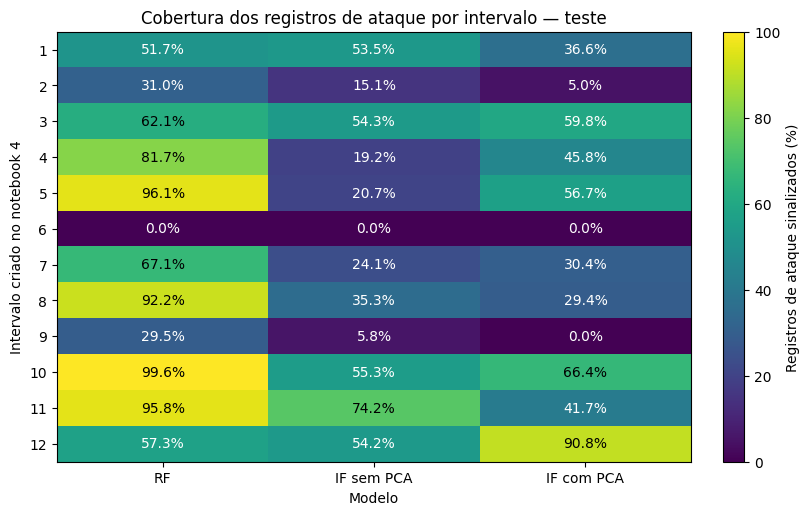

Segundos até o primeiro alerta dentro do intervalo:


modelo,RF,IF sem PCA,IF com PCA
intervalo_id,,,
1,45.0,45.0,46.0
2,17.0,20.0,24.0
3,16.0,16.0,24.0
4,15.0,24.0,26.0
5,0.0,44.0,21.0
6,NaN,NaN,NaN
7,26.0,31.0,27.0
8,4.0,9.0,13.0
9,70.0,72.0,NaN


In [8]:
fig, ax = plt.subplots(figsize=(8, max(4, 0.42 * len(cobertura))), layout='constrained')
imagem = ax.imshow(cobertura.to_numpy(), cmap='viridis', vmin=0, vmax=100, aspect='auto')
for (i, j), valor in np.ndenumerate(cobertura.to_numpy()):
    ax.text(j, i, f'{valor:.1f}%', ha='center', va='center', color='black' if valor > 60 else 'white')
ax.set_xticks(np.arange(len(MODELOS)), MODELOS)
ax.set_yticks(np.arange(len(cobertura)), cobertura.index.astype(str))
ax.set_xlabel('Modelo')
ax.set_ylabel('Intervalo criado no notebook 4')
ax.set_title('Cobertura dos registros de ataque por intervalo — teste')
fig.colorbar(imagem, ax=ax, label='Registros de ataque sinalizados (%)')
for extensao in ['png', 'pdf']:
    fig.savefig(ANALISE_DIR / f'cobertura_intervalos.{extensao}', dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)
print('Segundos até o primeiro alerta dentro do intervalo:')
display(atrasos.round(2))
cobertura.to_csv(ANALISE_DIR / 'cobertura_intervalos.csv')
atrasos.to_csv(ANALISE_DIR / 'primeiro_alerta_intervalos.csv', na_rep='NaN')


## 8. Localizar os falsos positivos no tempo

Este CSV foi produzido usando somente os registros realmente normais. A taxa
de cada faixa é `100 × falsos positivos / registros normais daquela faixa`.

As cinco faixas mostradas abaixo são escolhidas pela contagem de erros do RF,
para descrição posterior dos resultados. Isso não modifica os limiares nem as
previsões do teste. As curvas incluem todas as faixas disponíveis.


,Registros normais,FP RF,Taxa FP RF (%),Taxa FP IF sem PCA (%),Taxa FP IF com PCA (%)
hora,,,,,
2020-07-31 09:00:00,3338,3166,94.85,33.82,3.77
2020-07-31 10:00:00,3480,2951,84.80,18.85,1.55
2020-07-31 11:00:00,3338,1479,44.31,9.26,6.92
2020-07-31 08:00:00,3600,1372,38.11,16.97,3.03
2020-07-31 12:00:00,1801,823,45.70,16.32,0.33


As cinco faixas com mais FP do RF concentram 91.35% dos seus falsos positivos.


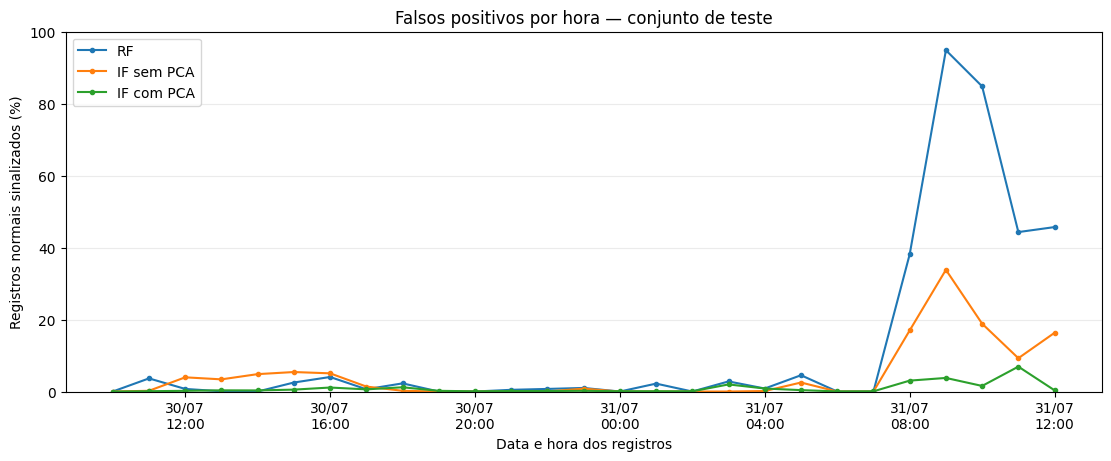

In [9]:
fp_hora = pd.read_csv(
    RESULTS_DIR / 'teste_falsos_positivos_por_hora.csv',
    index_col='hora', parse_dates=['hora'],
).sort_index()
if fp_hora.index.has_duplicates or fp_hora.index.isna().any():
    raise ValueError('Faixas horárias repetidas ou inválidas.')
if (fp_hora['Registros normais'] <= 0).any() or int(fp_hora['Registros normais'].sum()) != normais_teste:
    raise ValueError('Total de registros normais incompatível na análise por hora.')
for modelo in MODELOS:
    contagem = fp_hora[f'FP {modelo}']
    if (contagem < 0).any() or (contagem > fp_hora['Registros normais']).any():
        raise ValueError(f'Contagem de FP inválida por hora: {modelo}.')
    if int(contagem.sum()) != teste.loc[modelo, 'Falsos positivos']:
        raise ValueError(f'O CSV por hora e as métricas gerais não correspondem: {modelo}.')
    taxa_calculada = 100 * contagem / fp_hora['Registros normais']
    if not np.allclose(taxa_calculada, fp_hora[f'Taxa FP {modelo} (%)'], atol=0.01, rtol=0):
        raise ValueError(f'Taxa de FP incompatível por hora: {modelo}.')

top_horas_rf = fp_hora.sort_values('FP RF', ascending=False).head(5)
colunas_hora = ['Registros normais', 'FP RF'] + [f'Taxa FP {modelo} (%)' for modelo in MODELOS]
display(top_horas_rf[colunas_hora].round(2))
concentracao_fp_rf = divisao_segura(top_horas_rf['FP RF'].sum(), teste.loc['RF', 'Falsos positivos'])
print(f'As cinco faixas com mais FP do RF concentram {concentracao_fp_rf:.2%} dos seus falsos positivos.')
top_horas_rf.to_csv(ANALISE_DIR / 'cinco_faixas_mais_fp_rf.csv')

fig, ax = plt.subplots(figsize=(11, 4.5), layout='constrained')
for modelo in MODELOS:
    ax.plot(fp_hora.index, fp_hora[f'Taxa FP {modelo} (%)'], marker='o', markersize=3, color=CORES[modelo], label=modelo)
ax.set_title('Falsos positivos por hora — conjunto de teste')
ax.set_xlabel('Data e hora dos registros')
ax.set_ylabel('Registros normais sinalizados (%)')
ax.set_ylim(0, 100)
ax.xaxis.set_major_locator(mdates.HourLocator(interval=4))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m\n%H:%M'))
ax.grid(axis='y', alpha=0.25)
ax.legend()
for extensao in ['png', 'pdf']:
    fig.savefig(ANALISE_DIR / f'falsos_positivos_por_hora.{extensao}', dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)


## 9. Registrar a síntese calculada

A célula gera um texto com os números carregados e o salva em Markdown.
Os resultados ajustados da validação são os mesmos usados para selecionar os
cortes; a avaliação no teste permite observar seu comportamento em outro
período. A análise dos intervalos e dos falsos positivos é descritiva e mantém
as previsões originais.


In [10]:
maior_f1 = teste['F1-score'].max()
melhores_f1 = teste.index[np.isclose(teste['F1-score'], maior_f1, atol=1e-12, rtol=0)].tolist()
linhas = [
    '# Análise de resultados — HAI 21.03', '',
    '## Protocolo',
    'Treinamento: test1–test3; validação: test4; teste: test5. Modelos e limiares mantidos na etapa de teste.',
    'Os rótulos foram utilizados para selecionar os normais do treinamento dos IFs e para escolher os limiares na validação.', '',
    '## Teste',
    f'{total_teste} registros: {normais_teste} normais e {ataques_teste} rotulados como ataque.',
    f'A referência que prevê sempre normal alcançaria {acuracia_referencia:.2%} de acurácia e recall zero para ataque.', '',
]
for modelo in MODELOS:
    linha = teste.loc[modelo]
    linhas.append(
        f'- {modelo}: precisão {linha["Precisão"]:.2%}; recall {linha["Recall"]:.2%}; '
        f'F1 {linha["F1-score"]:.4f}; FP {int(linha["Falsos positivos"])}; FN {int(linha["Falsos negativos"])}.'
    )
linhas += [
    '', f'Maior F1 neste teste: {", ".join(melhores_f1)} ({maior_f1:.4f}).', '',
    '## Comparação dos IFs',
    f'Com PCA em relação a sem PCA: redução relativa de FP de {reducao_fp:.2%}; '
    f'variação de {int(com_pca["Verdadeiros positivos"] - sem_pca["Verdadeiros positivos"]):+d} registros de ataque detectados; '
    f'variação de recall de {100 * (com_pca["Recall"] - sem_pca["Recall"]):+.2f} pontos percentuais.', '',
    '## Intervalos',
    f'{len(cobertura)} trechos contínuos identificados pela regra do notebook 4. '
    f'Intervalos sem alerta em todos os modelos: {falhas_comuns}.',
]
for modelo in MODELOS:
    linha = resumo_intervalos_modelos.loc[modelo]
    linhas.append(f'- {modelo}: algum alerta em {int(linha["Intervalos com algum alerta"])} de {int(linha["Total de intervalos"])} intervalos.')
linhas += [
    '', '## Falsos positivos no tempo',
    f'As cinco faixas horárias com mais erros do RF concentram {concentracao_fp_rf:.2%} dos seus falsos positivos.', '',
    '## Alcance da análise',
    'O maior F1 agregado não garante presença de alerta em todos os intervalos. '
    'Os IDs de intervalo não foram equiparados aos cenários oficiais do HAI. '
    'As concentrações de erros e as diferenças entre períodos não estabelecem suas causas. '
    'As conclusões se referem às configurações e ao recorte temporal deste experimento.',
]
texto_sintese = '\n'.join(linhas) + '\n'
(ANALISE_DIR / 'sintese_resultados.md').write_text(texto_sintese, encoding='utf-8')
print(texto_sintese)
print('Arquivos da análise salvos em:', ANALISE_DIR)

exp.registrar("analise", f1_teste=teste["F1-score"].to_dict())


# Análise de resultados — HAI 21.03

## Protocolo
Treinamento: test1–test3; validação: test4; teste: test5. Modelos e limiares mantidos na etapa de teste.
Os rótulos foram utilizados para selecionar os normais do treinamento dos IFs e para escolher os limiares na validação.

## Teste
92401 registros: 90224 normais e 2177 rotulados como ataque.
A referência que prevê sempre normal alcançaria 97.64% de acurácia e recall zero para ataque.

- RF: precisão 10.95%; recall 60.54%; F1 0.1855; FP 10718; FN 859.
- IF sem PCA: precisão 16.08%; recall 35.00%; F1 0.2203; FP 3978; FN 1415.
- IF com PCA: precisão 52.11%; recall 41.34%; F1 0.4611; FP 827; FN 1277.

Maior F1 neste teste: IF com PCA (0.4611).

## Comparação dos IFs
Com PCA em relação a sem PCA: redução relativa de FP de 79.21%; variação de +138 registros de ataque detectados; variação de recall de +6.34 pontos percentuais.

## Intervalos
12 trechos contínuos identificados pela regra do notebook 4. Intervalos sem alerta em todos os model

## Como apresentar os resultados

1. Explique primeiro a divisão dos arquivos e o papel de cada etapa.
2. Diferencie o RF supervisionado do ajuste dos IFs com dados selecionados como normais.
3. Mostre o efeito do limiar na validação e depois os resultados do teste.
4. Compare precisão, recall, F1 e contagens de FP/FN; use a referência para contextualizar a acurácia.
5. Compare os dois IFs e examine os intervalos em que o resultado mudou.
6. Mostre a concentração de falsos alarmes no tempo e separe o que foi observado do que ainda precisa de investigação.

A avaliação por intervalo complementa as métricas por registro. Os gráficos
e a síntese estão disponíveis em `results/analise_resultados` após a execução.
